# **Naive Bayes Classification Challenge: End-to-End AI Pipeline**  
*From Data Cleaning to Model Comparison*  

In this hands-on challenge, **YOU** will go through a complete **AI/ML pipeline** using **Naive Bayes** classification. The dataset will have:  
✅ **Missing values** (requiring imputation)  
✅ **Categorical features** (requiring encoding)  
✅ **Text data** (if applicable, requiring TF-IDF/BOW)  
✅ **Numerical features** (for Gaussian Naive Bayes)  

---

## **Pipeline Steps**  
1. **Data Loading & Exploration**  
2. **Handling Missing Values**  
3. **Encoding Categorical Features**  
5. **Train-Test Split**  
6. **Naive Bayes from Scratch**  
7. **Naive Bayes using `scikit-learn`**  
8. **Model Comparison & Analysis**  

---

### **Learning Objectives**  
- Practice full ML workflow from raw data to evaluation  
- Compare manual vs. library implementations  
- Understand the impact of preprocessing decisions  

Let's begin!


# Data Loading & Exploration
**Objective**: Find and load the Titanic dataset, then perform initial exploration to identify data quality issues.


## Step 1: Import Required Libraries
## We'll use these key Python packages:
## - `pandas` for data manipulation
## - `numpy` for numerical operations
## - `matplotlib` and `seaborn` for visualization



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline



## Step 1: Download the Data
First, obtain the Titanic dataset from this reliable source:  
📥 [Download Titanic Dataset](https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv)


## Step 2: Load into Python
Use pandas to load the data directly from URL or local file:



###Load directly from web (easiest method)
data = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")

 Or if downloaded locally:

 data = pd.read_csv("titanic.csv")

In [2]:
data = pd.read_csv(
    "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
)

print("Dataset loaded successfully")
print(data.shape)

Dataset loaded successfully
(891, 12)


## Data Inspection

### Displaying All Columns

pd.set_option('display.max_columns', None)  # Show all columns without truncation

print("First 5 rows:")

display(data.head())  # Interactive display of first 5 records

In [3]:
pd.set_option('display.max_columns', None)

print("First 5 rows:")
display(data.head())

First 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
data=pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")

#Statistical Summary

### Numerical Features Analysis

print("Numerical features summary:")
display(data.describe())

In [5]:
print("Numerical features summary:")
display(data.describe())

Numerical features summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


#Missing Value Analysis

### Understanding Missing Data

print("Missing values per column:")

missing = data.isnull().sum()



In [6]:
print("Missing values per column:")

missing = data.isnull().sum()

print(missing)

Missing values per column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64



#Target Variable Distribution
Essential for understanding class imbalance

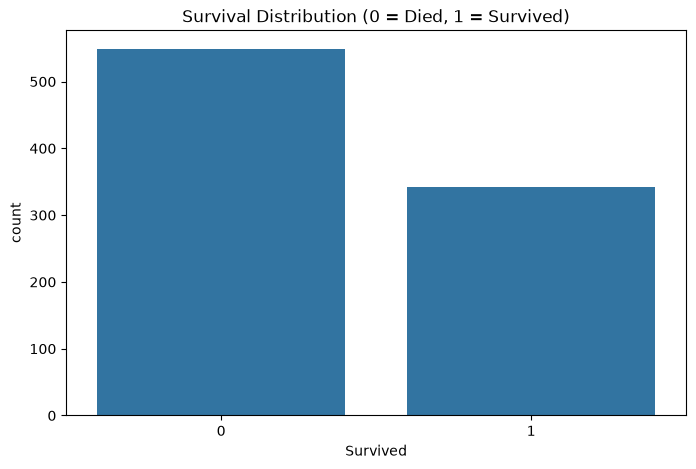

In [7]:
plt.figure(figsize=(8,5))
sns.countplot(x='Survived', data=data)
plt.title("Survival Distribution (0 = Died, 1 = Survived)")
plt.show()

## Handling Missing Values & Categorical Encoding

### 1. Filling Missing Values

#### Common Strategies:

from sklearn.impute import SimpleImputer

##For numerical columns (Age, Fare)
num_imputer = SimpleImputer(strategy='median')  # Alternatives: 'mean', 'constant'

data['Age'] = num_imputer.fit_transform(data[['Age']])

## For categorical columns (Embarked)
cat_imputer = SimpleImputer(strategy='most_frequent')

data['Embarked'] = cat_imputer.fit_transform(data[['Embarked']]).ravel()

In [8]:
from sklearn.impute import SimpleImputer

# Numerical column: Age
num_imputer = SimpleImputer(strategy='median')

data['Age'] = num_imputer.fit_transform(data[['Age']])

# Categorical column: Embarked
cat_imputer = SimpleImputer(strategy='most_frequent')

data['Embarked'] = cat_imputer.fit_transform(data[['Embarked']]).ravel()

print("Missing values handled successfully!")

Missing values handled successfully!


In [9]:
# complete missing values
print(data.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64


In [10]:
# remove unnecessary column
data_model = data[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Survived']].copy()

display(data_model.head())

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,3,male,22.0,1,0,7.2500,S,0
1,1,female,38.0,1,0,71.2833,C,1
2,3,female,26.0,0,0,7.9250,S,1
3,1,female,35.0,1,0,53.1000,S,1
4,3,male,35.0,0,0,8.0500,S,0


# Label Encoding: Essential Guide

## What is Label Encoding?
Converts categorical text values into numeric labels:
- Assigns a unique integer to each category
- Preserves no mathematical relationship between values

Before:           After:

['Dog']           [0]

['Cat']           [1]

['Bird']          [2]


# Initialize and fit
le = LabelEncoder()
encoded_colors = le.fit_transform(colors)

In [11]:
# label endonding in sex or embarked
from sklearn.preprocessing import LabelEncoder

# Encode Sex
sex_encoder = LabelEncoder()
data_model['Sex'] = sex_encoder.fit_transform(data_model['Sex'])

# Encode Embarked
embarked_encoder = LabelEncoder()
data_model['Embarked'] = embarked_encoder.fit_transform(data_model['Embarked'])

display(data_model.head())

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,3,1,22.0,1,0,7.2500,2,0
1,1,0,38.0,1,0,71.2833,0,1
2,3,0,26.0,0,0,7.9250,2,1
3,1,0,35.0,1,0,53.1000,2,1
4,3,1,35.0,0,0,8.0500,2,0


# Data Splitting: Train-Test Validation

## Why Split Data?
- **Train set**: Used to train the model (~70-80%)
- **Test set**: Used to evaluate final performance (~20-30%)
- Prevents overfitting by testing on unseen data

## Basic Splitting (sklearn)

from sklearn.model_selection import train_test_split

## Features (X) and Target (y)
X = titanic.drop('Survived', axis=1)
y = titanic['Survived']

## Split with 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,  # For reproducibility
    stratify=y       # Preserves class distribution
)

print(f"Train size: {len(X_train)} samples")

print(f"Test size: {len(X_test)} samples")

In [ ]:
X = data_model.drop('Survived', axis=1)
y = data_model['Survived']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train size:", len(X_train))
print("Test size:", len(X_test))

Train size: 712
Test size: 179


# Naive Bayes Implementation from scratch

## The 3-Step Process

1. **Calculate Priors (P(y))**  
   - Estimate class probabilities from training data  
   - Example: In Titanic dataset, P(Survived=1) ≈ 38%, P(Survived=0) ≈ 62%

2. **Compute Likelihoods (P(X|y))**  
   - For continuous features: Assume Gaussian distribution  
     ```math
     P(x_i|y) = \frac{1}{\sqrt{2\pi\sigma_y^2}}e^{-\frac{(x-\mu_y)^2}{2\sigma_y^2}}
     ```
   - For categorical features: Use frequency counts  
   - *Naive* assumption: Features are conditionally independent  
     ```math
     P(X|y) = \prod_{i=1}^n P(x_i|y)
     ```

3. **Predict Using Posteriors**  
   - Apply Bayes' Theorem (ignoring denominator P(X)):  
     ```math
     P(y|X) \propto P(y) \times \prod_{i=1}^n P(x_i|y)
     ```
   - Practical implementation uses log probabilities:  
     ```python
     log_posterior = log(P(y)) + sum(log(P(x_i|y)))
     ```
   - Final prediction: Class with highest log posterior

## Titanic Example Walkthrough
For a passenger with [Age=25, Fare=50]:

1. **Calculate for Survived=0**  
   - log P(Age=25|0) = -1.2  
   - log P(Fare=50|0) = -4.5  
   - log P(0) = -0.48  
   - **Total**: -6.18

2. **Calculate for Survived=1**  
   - log P(Age=25|1) = -1.5  
   - log P(Fare=50|1) = -3.8  
   - log P(1) = -0.92  
   - **Total**: -6.22

3. **Prediction**: argmax(-6.18, -6.22) → Survived=0



In [ ]:
# Naive Bayes from Scratch

continuous_features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Sex', 'Embarked']

# Calculate mean and variance
means = {}
variances = {}

for c in classes:
    X_c = X_train[y_train == c]

    means[c] = X_c[continuous_features].mean()
    variances[c] = X_c[continuous_features].var()


# Gaussian probability
def gaussian_probability(x, mean, variance):
    return (1 / np.sqrt(2 * np.pi * variance)) * np.exp(
        -((x - mean) ** 2) / (2 * variance)
    )


# Prediction function
def predict_one(row):

    scores = {}

    for c in classes:

        # Prior
        score = priors[c]

        X_c = X_train[y_train == c]

        # Continuous features
        for feature in continuous_features:

            score *= gaussian_probability(
                row[feature],
                means[c][feature],
                variances[c][feature]
            )

        # Categorical features
        for feature in categorical_features:

            count = (X_c[feature] == row[feature]).sum()
            total = len(X_c)
            number_of_categories = X_train[feature].nunique()

            probability = (count + 1) / (
                total + number_of_categories
            )

            score *= probability

        scores[c] = score

    return max(scores, key=scores.get)


# Predictions
y_pred_scratch = np.array([
    predict_one(row)
    for _, row in X_test.iterrows()
])


# Accuracy
from sklearn.metrics import accuracy_score

accuracy_scratch = accuracy_score(
    y_test,
    y_pred_scratch
)

print("Naive Bayes from Scratch Accuracy:", accuracy_scratch)

Naive Bayes from Scratch Accuracy: 0.7374301675977654


# scikit-learn's Naive Bayes

### 1. Overview of Implementations

### GaussianNB
- **Use Case**: Continuous features assumed to follow normal distribution
- **Math**: Uses Gaussian probability density function
- **Best For**: Medical diagnosis, sensor data

### MultinomialNB
- **Use Case**: Discrete counts (word frequencies in text)
- **Math**: Uses multinomial distribution
- **Best For**: Text classification, recommendation systems

### BernoulliNB
- **Use Case**: Binary/boolean features
- **Math**: Binomial distribution
- **Best For**: Spam detection, document categorization

### ComplementNB
- **Use Case**: Imbalanced text datasets
- **Math**: Adapts MultinomialNB for class imbalance
- **Best For**: Sentiment analysis with skewed classes

### CategoricalNB
- **Use Case**: Categorical features with discrete values
- **Math**: Categorical distribution
- **Best For**: Survey data, categorical attributes

## 2. Detailed Implementation

### GaussianNB for Titanic Survival
```python
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Create pipeline with scaling
nb_pipe = make_pipeline(
    StandardScaler(),
    GaussianNB(var_smoothing=1e-9)
)

# Fit and predict
nb_pipe.fit(X_train, y_train)
y_proba = nb_pipe.predict_proba(X_test)

# Access learned parameters
gnb = nb_pipe.named_steps['gaussiannb']
print("Class means:\n", gnb.theta_)
print("Class variances:\n", gnb.sigma_)

In [ ]:
from sklearn.naive_bayes import GaussianNB

# Create model
nb_model = GaussianNB()

# Train model
nb_model.fit(X_train, y_train)

# Make predictions
y_pred_sklearn = nb_model.predict(X_test)

# Calculate accuracy
accuracy_sklearn = accuracy_score(y_test, y_pred_sklearn)

print("Naive Bayes using Scikit-learn Accuracy:", accuracy_sklearn)

Naive Bayes using Scikit-learn Accuracy: 0.7821229050279329


# Model Evaluation: Accuracy & Confusion Matrix

## Key Metrics Explained

**1. Accuracy**  
- Measures overall correctness: `(TP + TN) / (TP + TN + FP + FN)`  
- Best for balanced datasets  
- **Limitation**: Misleading with class imbalance  

**2. Confusion Matrix**  
Visualizes model performance across classes:

In [ ]:
# Essential imports
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
print("Model Comparison")
print("-----------------")

print("Naive Bayes from Scratch:",
      round(accuracy_scratch * 100, 2), "%")

print("Naive Bayes using Scikit-learn:",
      round(accuracy_sklearn * 100, 2), "%")

Model Comparison
-----------------


NameError: name 'accuracy_scratch' is not defined